# Analisis Time Series

# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels as sm
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima_model import ARMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

# Data Understanding

## Import Dataset dan Sumber, Nama, Format, serta Tujuan Dataset

In [2]:
data = pd.read_csv("Time Series - data train.csv") # Membaca file csv

In [3]:
df = pd.DataFrame(data) # Mengubahnya menjadi DataFrame
df

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.000,0
1,1,2013-01-01,1,BABY CARE,0.000,0
2,2,2013-01-01,1,BEAUTY,0.000,0
3,3,2013-01-01,1,BEVERAGES,0.000,0
4,4,2013-01-01,1,BOOKS,0.000,0
...,...,...,...,...,...,...
3000883,3000883,2017-08-15,9,POULTRY,438.133,0
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8


In [4]:
df.info() # Untuk mengetahui jumlah baris dan kolom. Mengetahui missing value tiap kolom, nama nama kolom, dan tipe data tiap kolom

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         str    
 2   store_nbr    int64  
 3   family       str    
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 196.8 MB


In [5]:
df.describe() # Untuk mengetahui informasi statistik deskriptif pada kolom dengan tipe data integer dan float

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


## Data Exploration

### Membuat Copy Dataset

In [6]:
df_copy = df.copy() # Membuat copy dataset

### Cek Inkonsistensi Data

In [7]:
inkonsistensi = df_copy.select_dtypes(include=["str"]).columns # Mengambil nama kolom dengan tipe data string

In [8]:
for i in inkonsistensi : # Memeriksa inkonsistensi data pada kolom dengan tipe data string
    print(f"Kolom {i} :")
    print(df_copy[i].unique())
    print("\n")

Kolom date :
<ArrowStringArray>
['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04', '2013-01-05',
 '2013-01-06', '2013-01-07', '2013-01-08', '2013-01-09', '2013-01-10',
 ...
 '2017-08-06', '2017-08-07', '2017-08-08', '2017-08-09', '2017-08-10',
 '2017-08-11', '2017-08-12', '2017-08-13', '2017-08-14', '2017-08-15']
Length: 1684, dtype: str


Kolom family :
<ArrowStringArray>
[                'AUTOMOTIVE',                  'BABY CARE',
                     'BEAUTY',                  'BEVERAGES',
                      'BOOKS',               'BREAD/BAKERY',
                'CELEBRATION',                   'CLEANING',
                      'DAIRY',                       'DELI',
                       'EGGS',               'FROZEN FOODS',
                  'GROCERY I',                 'GROCERY II',
                   'HARDWARE',         'HOME AND KITCHEN I',
        'HOME AND KITCHEN II',            'HOME APPLIANCES',
                  'HOME CARE',                 'LADIESWEAR',
        

### Jumlah dan Persentase Missing Value

In [9]:
df_copy_miss = df_copy.isnull().sum() # Mencari jumlah missing value
df_copy_miss_percentage = df_copy_miss / len(df_copy) * 100 # Mencari persentase missing value

In [10]:
print(f"Jumlah missing value : \n{df_copy_miss}")
print(f"Persentase missing value : \n{df_copy_miss_percentage}")

Jumlah missing value : 
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
Persentase missing value : 
id             0.0
date           0.0
store_nbr      0.0
family         0.0
sales          0.0
onpromotion    0.0
dtype: float64


### Jumlah dan Persentase Duplicate Value

In [11]:
duplicate_all = df_copy.duplicated().sum() # Memeriksa jumlah duplicate value berdasarkan tiap baris
persent_duplicate_all = duplicate_all /len(df_copy)*100 # Menghitung persentase duplicate value
print(f"Jumlah Baris yang duplikat = {duplicate_all}")
print(f"Persentase Baris yang duplikat = {persent_duplicate_all:.2f}%")

Jumlah Baris yang duplikat = 0
Persentase Baris yang duplikat = 0.00%


### Encoder Kolom Kategori Untuk Periksa Outlier

In [12]:
from sklearn.preprocessing import LabelEncoder # Memanggil Library untuk LabelEncoder

In [13]:
le = LabelEncoder()

In [14]:
'''Membuat LabelEncoder pada tiap Kolom dengan tipe data string'''
df_copy["family_code"] = le.fit_transform(df_copy["family"])

### Jumlah dan Persentase Outlier Dengan IQR

In [15]:
'''Membuat Variabel Baru Untuk Mengambil Nama Kolom Dengan Tipe Data Numerikal'''
kolom_numerik = df_copy.select_dtypes(include=["float64", "int64"]).columns

In [16]:
kolom_numerik

Index(['id', 'store_nbr', 'sales', 'onpromotion', 'family_code'], dtype='str')

In [17]:
for i in kolom_numerik :
    Q1 = df_copy[i].quantile(0.25)
    Q3 = df_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier = (df_copy[i] < lower) | (df_copy[i] > upper)
    jumlah_outlier = outlier.sum() # Mengetahui jumlah outlier pada kolom
    persentase_outlier = jumlah_outlier/len(outlier) * 100 # Mengetahui persentase outlier pada kolom
    print(f"Jumlah Outlier pada Kolom {i} : {jumlah_outlier}")
    print(f"Persentase Outlier pada Kolom {i} : {persentase_outlier:.2f}%\n")

Jumlah Outlier pada Kolom id : 0
Persentase Outlier pada Kolom id : 0.00%

Jumlah Outlier pada Kolom store_nbr : 0
Persentase Outlier pada Kolom store_nbr : 0.00%

Jumlah Outlier pada Kolom sales : 447105
Persentase Outlier pada Kolom sales : 14.90%

Jumlah Outlier pada Kolom onpromotion : 611329
Persentase Outlier pada Kolom onpromotion : 20.37%

Jumlah Outlier pada Kolom family_code : 0
Persentase Outlier pada Kolom family_code : 0.00%



In [18]:
ringkasan_family_sales = (
    df_copy.groupby("family")["sales"]
    .agg(
        jumlah_data="count",
        median="median",
        rata_rata="mean",
        maksimum="max",
        std="std"
    )
    .sort_values("rata_rata", ascending=False)
)

ringkasan_family_sales

,jumlah_data,median,rata_rata,maksimum,std
family,,,,,
GROCERY I,90936,3185.0000,3776.972100,124717.000,2874.208845
BEVERAGES,90936,1784.0000,2385.793151,25413.000,2307.882305
PRODUCE,90936,398.2905,1349.352123,17850.615,2186.481332
CLEANING,90936,938.0000,1072.416744,11377.000,734.681493
DAIRY,90936,520.0000,709.154889,5636.000,671.949638
BREAD/BAKERY,90936,401.0000,463.336254,4551.298,368.246367
POULTRY,90936,205.7430,350.532292,12143.201,400.511631
MEATS,90936,224.9365,341.849965,89576.360,455.908498
PERSONAL CARE,90936,222.0000,270.432513,7504.000,226.512007


In [19]:
ringkasan_family_promo = (
    df_copy.groupby("family")["onpromotion"]
    .agg(
        jumlah_data="count",
        median="median",
        rata_rata="mean",
        maksimum="max",
        std="std"
    )
    .sort_values("rata_rata", ascending=False)
)

ringkasan_family_promo

,jumlah_data,median,rata_rata,maksimum,std
family,,,,,
GROCERY I,90936,5.0,21.056578,741,33.305691
PRODUCE,90936,0.0,12.293492,252,41.135179
BEVERAGES,90936,2.0,9.973586,342,16.799104
DAIRY,90936,1.0,8.013405,167,19.615770
CLEANING,90936,1.0,7.270575,285,13.219624
DELI,90936,0.0,6.414577,81,15.090628
BREAD/BAKERY,90936,0.0,3.643101,104,10.451534
MEATS,90936,0.0,3.343318,56,10.394083
PERSONAL CARE,90936,0.0,2.715404,99,4.636477


### Cek Distribusi Data Dengan Uji D'Agostino-Pearson

In [20]:
from scipy.stats import normaltest

In [21]:
for i in kolom_numerik :
    statistic, p_value = normaltest(df_copy[i])

    print(f"Kolom {i}")
    print("Statistic:", statistic)
    print("P-value:", p_value)

    alpha = 0.05

    if p_value < alpha:
        print("Tolak H0: Data tidak berdistribusi normal")
    else:
        print("Gagal menolak H0: Tidak cukup bukti bahwa data tidak normal")
    print("\n")

Kolom id
Statistic: 2666035.3334195283
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom store_nbr
Statistic: 2686641.4780145814
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom sales
Statistic: 4060244.308899146
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom onpromotion
Statistic: 5009961.874802569
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom family_code
Statistic: 2721810.743340679
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal




### Cek Distribusi Data Dengan Histogram

In [22]:
numerik = df_copy.select_dtypes(include=["float64", "int64"])

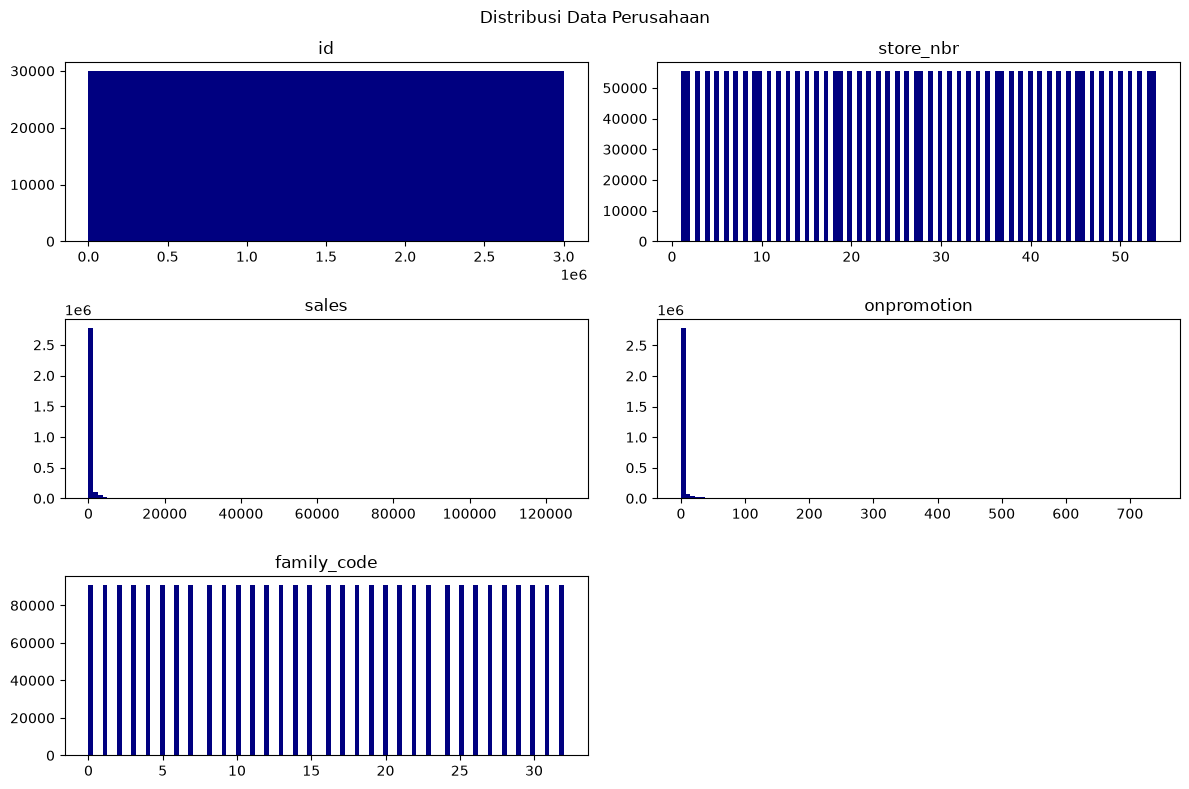

In [23]:
numerik.hist(color='navy', figsize=(12,8), bins=100, grid=False)
plt.suptitle("Distribusi Data Perusahaan")
plt.tight_layout()
plt.show()

### Insight Berdasarkan Hasil Eksplorasi

# Data Preparation

## Data Cleaning

### Menangani Tipe Data

In [24]:
df_copy["id"] = df_copy["id"].astype("category")
df_copy["store_nbr"] = df["store_nbr"].astype("category")
df_copy["date"] = pd.to_datetime(df_copy["date"], format="%Y-%m-%d")

In [25]:
df_copy.info() # Memeriksa kembali tipe data

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 7 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           category      
 1   date         datetime64[us]
 2   store_nbr    category      
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
 6   family_code  int64         
dtypes: category(2), datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 182.5 MB


# EDA (Analisa Data)

## Analisis Univariat

### Rata Rata Sales dan Total Setiap Tahun

In [26]:
df_copy = df_copy.sort_values(by=("date"))

In [27]:
df_copy["tahun"] = df_copy["date"].dt.year

In [28]:
sales_tahun = df_copy.groupby("tahun").agg(
    rata_rata_sales = ("sales", "mean"),
    jumlah_sales = ("sales", "sum")
).reset_index()

In [29]:
sales_tahun

,tahun,rata_rata_sales,jumlah_sales
0,2013,216.479530,1.404190e+08
1,2014,322.939786,2.094742e+08
2,2015,371.357193,2.408801e+08
3,2016,443.790297,2.886545e+08
4,2017,480.124466,1.942171e+08


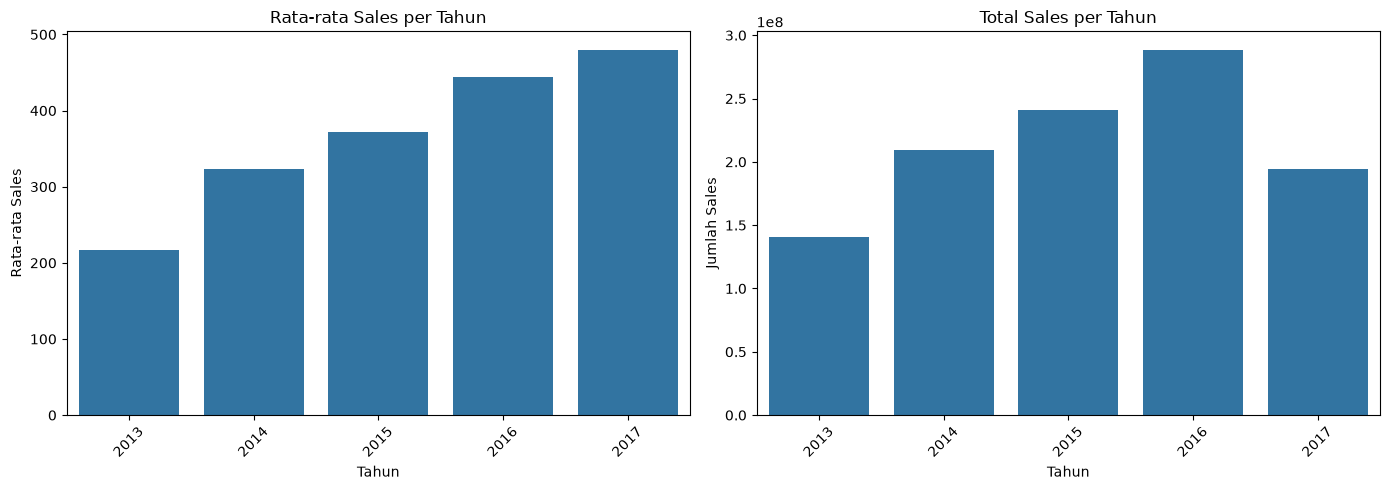

In [30]:
plt.figure(figsize=(14, 5))

# Grafik 1: Rata-rata sales
plt.subplot(1, 2, 1)
sns.barplot(
    data=sales_tahun,
    x="tahun",
    y="rata_rata_sales"
)
plt.title("Rata-rata Sales per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Rata-rata Sales")
plt.xticks(rotation=45)

# Grafik 2: Total sales
plt.subplot(1, 2, 2)
sns.barplot(
    data=sales_tahun,
    x="tahun",
    y="jumlah_sales"
)
plt.title("Total Sales per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
df_copy[df_copy["tahun"]==2017]["date"].max()

Timestamp('2017-08-15 00:00:00')

### Rata Rata dan Total Sales Setiap Bulan

In [32]:
df_copy["bulan"] = df_copy["date"].dt.month

In [33]:
sales_bulan = df_copy.groupby("bulan").agg(
    rata_rata_sales = ("sales", "mean"),
    jumlah_sales = ("sales", "sum")
).reset_index()

In [34]:
sales_bulan

,bulan,rata_rata_sales,jumlah_sales
0,1,341.921554,9.444215e+07
1,2,320.928869,8.063723e+07
2,3,352.009294,9.722849e+07
3,4,339.199841,9.066812e+07
4,5,341.765820,9.439914e+07
5,6,353.597842,9.451670e+07
6,7,374.219111,1.033631e+08
7,8,336.992535,8.347238e+07
8,9,362.297418,7.747368e+07
9,10,362.407132,8.008038e+07


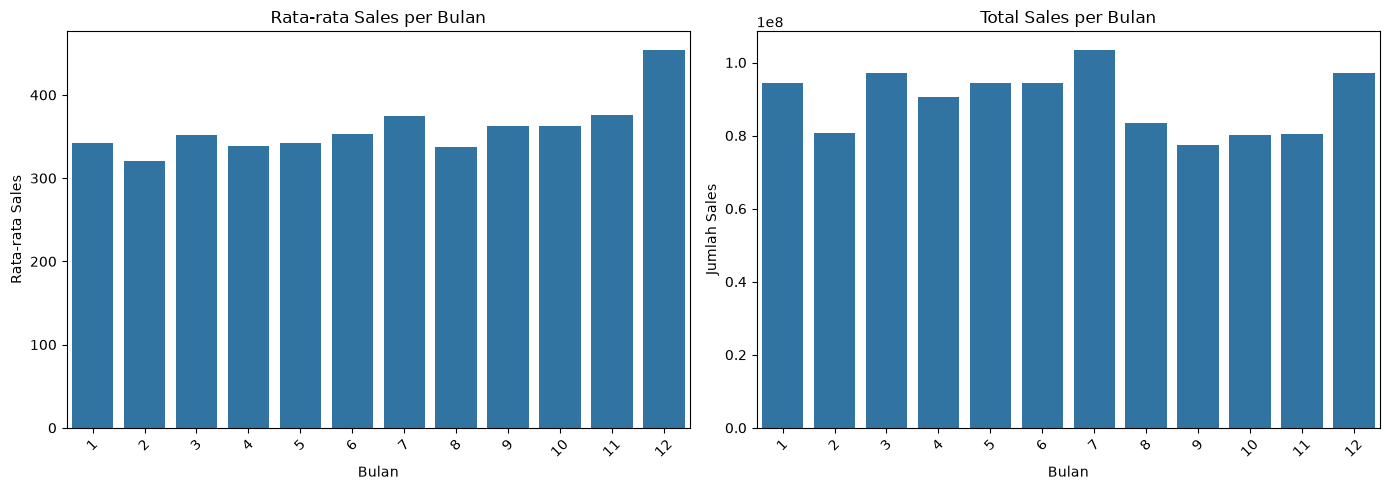

In [35]:
plt.figure(figsize=(14, 5))

# Grafik 1: Rata-rata sales
plt.subplot(1, 2, 1)
sns.barplot(
    data=sales_bulan,
    x="bulan",
    y="rata_rata_sales"
)
plt.title("Rata-rata Sales per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Sales")
plt.xticks(rotation=45)

# Grafik 2: Total sales
plt.subplot(1, 2, 2)
sns.barplot(
    data=sales_bulan,
    x="bulan",
    y="jumlah_sales"
)
plt.title("Total Sales per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Rata Rata dan Total Sales Setiap Hari

In [36]:
df_copy["hari"] = df_copy["date"].dt.dayofweek + 1
df_copy["nama_hari"] = df_copy["date"].dt.day_name()

In [37]:
sales_hari = df_copy.groupby(["hari", "nama_hari"]).agg(
    rata_rata_sales=("sales", "mean"),
    jumlah_sales=("sales", "sum")
).reset_index()

In [38]:
sales_hari

,hari,nama_hari,rata_rata_sales,jumlah_sales
0,1,Monday,346.544732,1.488278e+08
1,2,Tuesday,319.823843,1.379221e+08
2,3,Wednesday,332.909401,1.423787e+08
3,4,Thursday,283.540517,1.212646e+08
4,5,Friday,325.238138,1.390978e+08
5,6,Saturday,433.336472,1.861015e+08
6,7,Sunday,463.085366,1.980523e+08


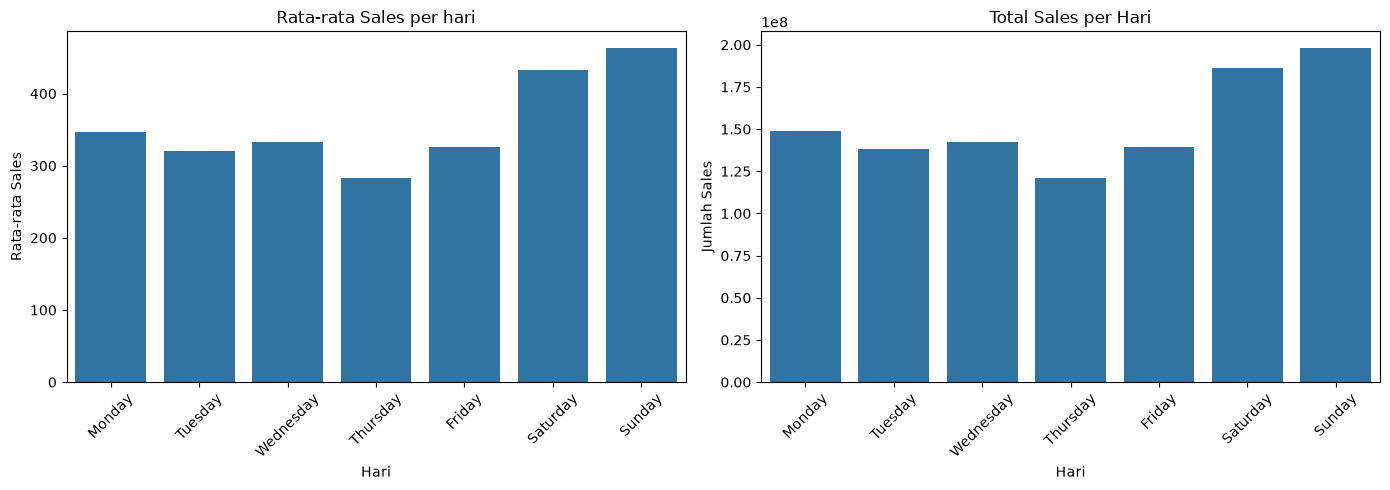

In [39]:
plt.figure(figsize=(14, 5))

# Grafik 1: Rata-rata sales
plt.subplot(1, 2, 1)
sns.barplot(
    data=sales_hari,
    x="nama_hari",
    y="rata_rata_sales"
)
plt.title("Rata-rata Sales per hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Sales")
plt.xticks(rotation=45)

# Grafik 2: Total sales
plt.subplot(1, 2, 2)
sns.barplot(
    data=sales_hari,
    x="nama_hari",
    y="jumlah_sales"
)
plt.title("Total Sales per Hari")
plt.xlabel("Hari")
plt.ylabel("Jumlah Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Analisis Bivariat

### Jumlah Promosi Setiap Hari

In [40]:
promosi = df_copy.groupby(["hari", "nama_hari"]).agg(
    jumlah_promosi=("onpromotion", "sum")
).reset_index()

In [41]:
promosi

,hari,nama_hari,jumlah_promosi
0,1,Monday,769911
1,2,Tuesday,1065643
2,3,Wednesday,1766767
3,4,Thursday,868989
4,5,Friday,1598481
5,6,Saturday,834192
6,7,Sunday,906639


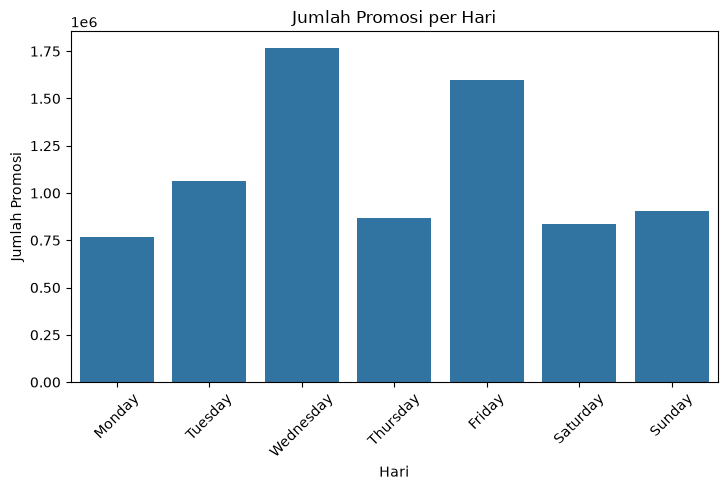

In [42]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(
    data=promosi,
    x="nama_hari",
    y="jumlah_promosi"
)
plt.title("Jumlah Promosi per Hari")
plt.xlabel("Hari")
plt.ylabel("Jumlah Promosi")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Rata Rata dan Total Sales Kategori Produk pada Hari Kamis

In [43]:
produk = df_copy[df_copy["nama_hari"]=="Thursday"].groupby("family").agg(
    rata_rata_sales=("sales", "mean"),
    jumlah_sales=("sales", "sum")
).reset_index().sort_values(by=("jumlah_sales")).head(5)

In [44]:
produk

,family,rata_rata_sales,jumlah_sales
4,BOOKS,0.061497,797.0
1,BABY CARE,0.090664,1175.0
17,HOME APPLIANCES,0.365509,4737.0
14,HARDWARE,0.978704,12684.0
31,SCHOOL AND OFFICE SUPPLIES,2.199306,28503.0


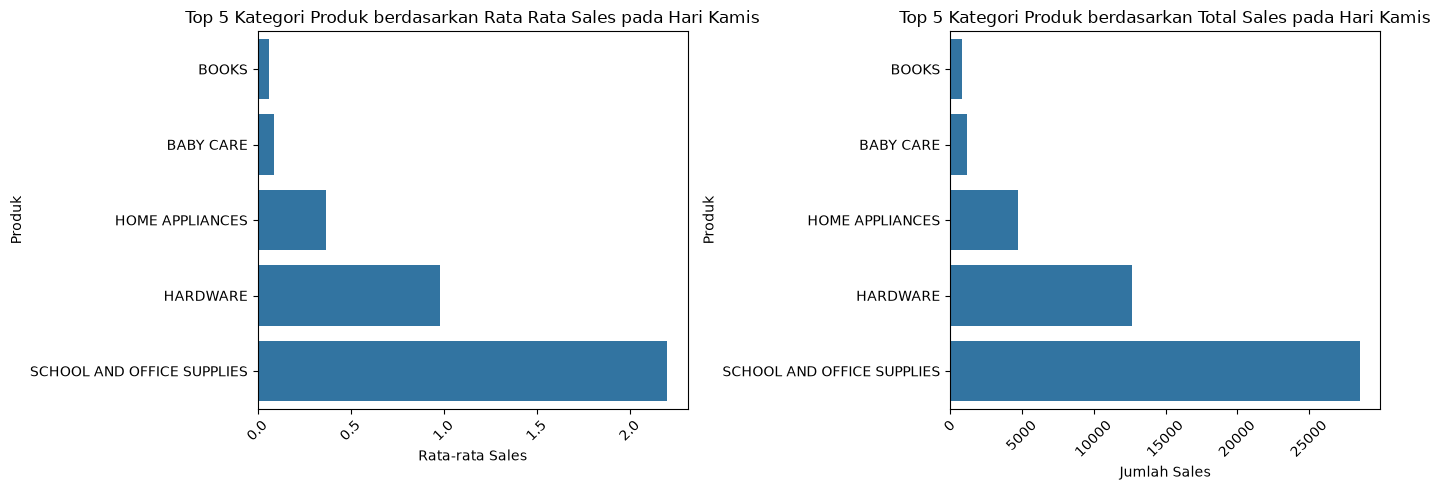

In [45]:
plt.figure(figsize=(14, 5))

# Grafik 1: Rata-rata sales
plt.subplot(1, 2, 1)
sns.barplot(
    data=produk,
    y="family",
    x="rata_rata_sales"
)
plt.title("Top 5 Kategori Produk berdasarkan Rata Rata Sales pada Hari Kamis")
plt.ylabel("Produk")
plt.xlabel("Rata-rata Sales")
plt.xticks(rotation=45)

# Grafik 2: Total sales
plt.subplot(1, 2, 2)
sns.barplot(
    data=produk,
    y="family",
    x="jumlah_sales"
)
plt.title("Top 5 Kategori Produk berdasarkan Total Sales pada Hari Kamis")
plt.ylabel("Produk")
plt.xlabel("Jumlah Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Rata Rata dan Total Sales Toko pada Hari Kamis

In [46]:
toko = df_copy[df_copy["nama_hari"]=="Thursday"].groupby("store_nbr").agg(
    rata_rata_sales=("sales", "mean"),
    jumlah_sales=("sales", "sum")
).reset_index().sort_values(by=("jumlah_sales")).head(5)

In [47]:
toko

,store_nbr,rata_rata_sales,jumlah_sales
51,52,37.872254,299948.254040
21,22,62.455262,494645.678999
31,32,98.721287,781872.592496
25,26,106.632689,844530.893974
34,35,120.481801,954215.867611


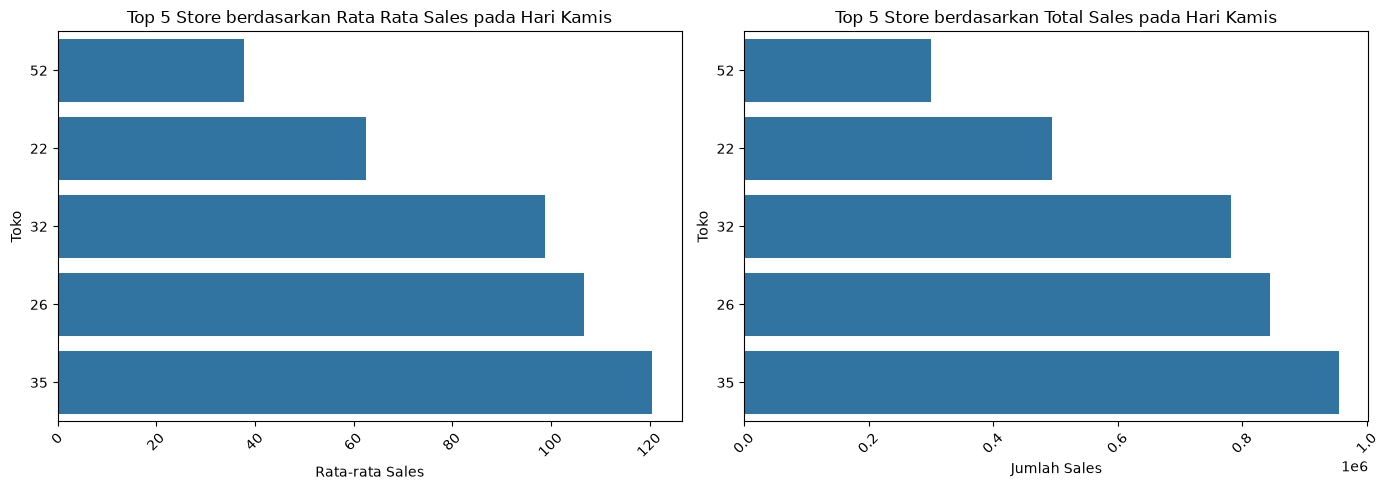

In [48]:
plt.figure(figsize=(14, 5))

# Grafik 1: Rata-rata sales
plt.subplot(1, 2, 1)
sns.barplot(
    data=toko,
    y="store_nbr",
    x="rata_rata_sales",
    order=toko["store_nbr"]
)
plt.title("Top 5 Store berdasarkan Rata Rata Sales pada Hari Kamis")
plt.ylabel("Toko")
plt.xlabel("Rata-rata Sales")
plt.xticks(rotation=45)

# Grafik 2: Total sales
plt.subplot(1, 2, 2)
sns.barplot(
    data=toko,
    y="store_nbr",
    x="jumlah_sales",
    order=toko["store_nbr"]
)
plt.title("Top 5 Store berdasarkan Total Sales pada Hari Kamis")
plt.ylabel("Toko")
plt.xlabel("Jumlah Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Hubungan Kolom Numerik

In [49]:
numerik = df.select_dtypes(include=("float64", "int64"))

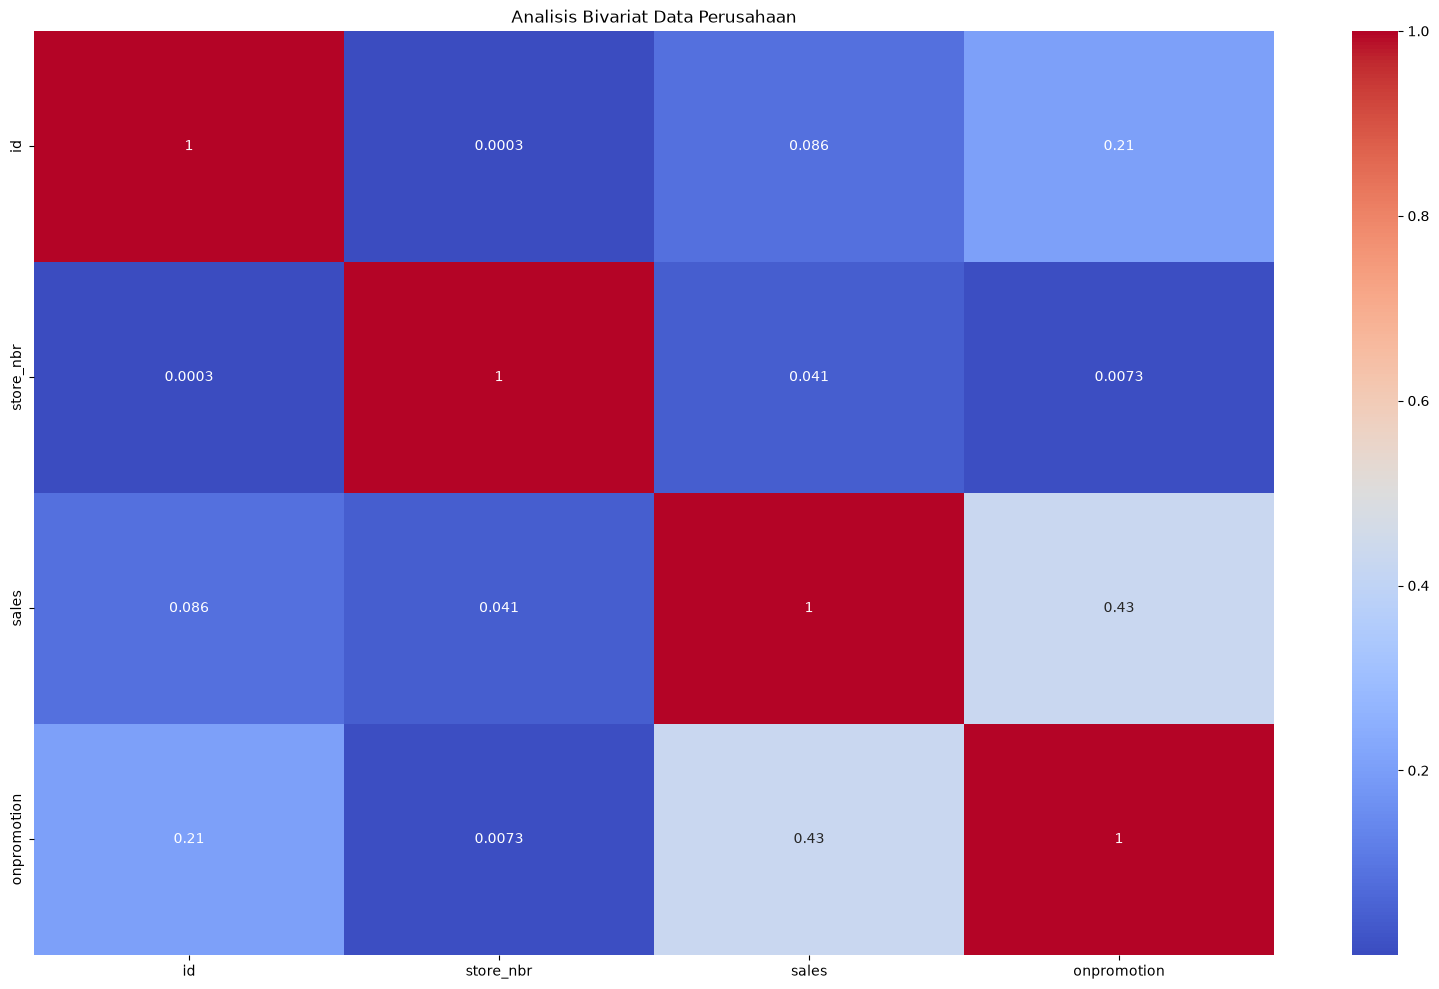

In [50]:
df_corr = numerik.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

## Analisis Multivariat

### Heatmap Hubungan Sales dan Onpromotion Berdasarkan Toko dan Kategori Produk

In [51]:
# Top 5 store dengan total sales terendah
top5_store = (
    df_copy.groupby("store_nbr")["sales"]
    .sum()
    .nsmallest(5)
    .index
)

# Top 5 family dengan total sales terendah
top5_family = (
    df_copy.groupby("family")["sales"]
    .sum()
    .nsmallest(5)
    .index
)

# Filter kombinasi top 5 store dan top 5 family
df_heatmap = df_copy[
    df_copy["store_nbr"].isin(top5_store) &
    df_copy["family"].isin(top5_family)
]

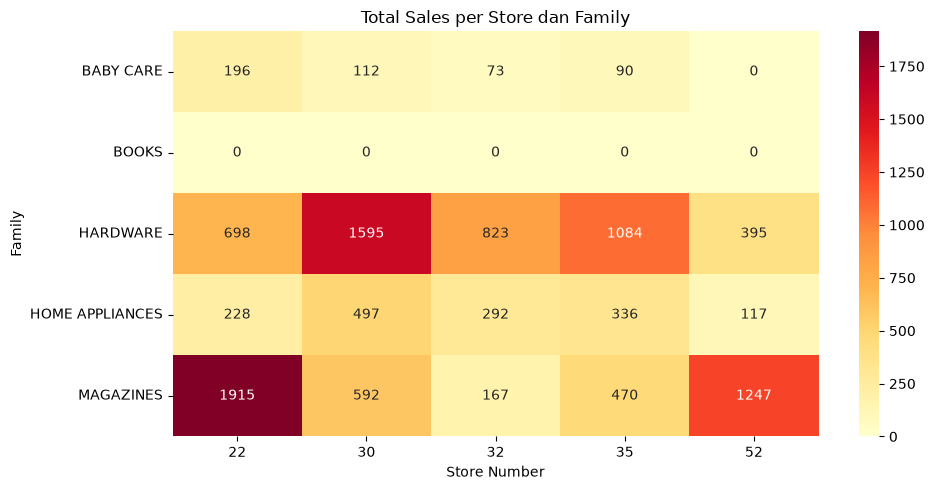

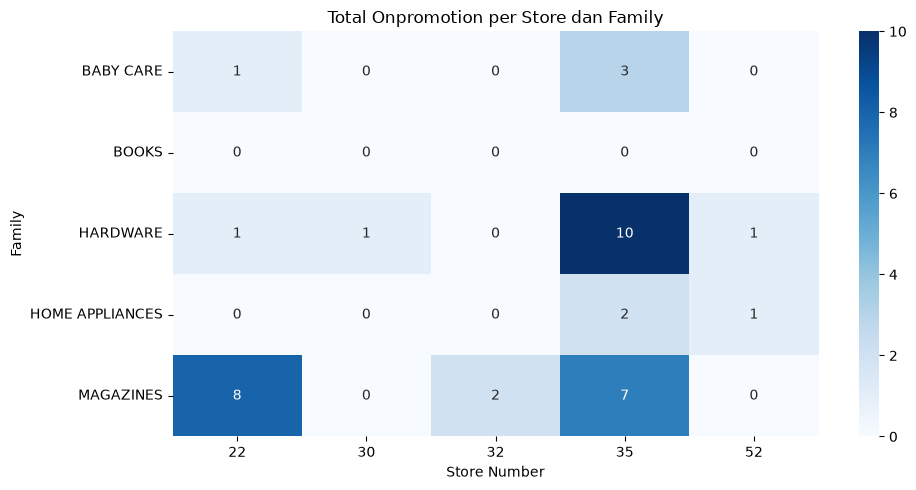

In [52]:
# Agregasi sales dan jumlah item yang sedang promosi
df_promo = (
    df_heatmap.groupby(["family", "store_nbr"])
    .agg(
        total_sales=("sales", "sum"),
        total_onpromotion=("onpromotion", "sum")
    )
    .reset_index()
)

# Buat heatmap sales
pivot_sales = df_promo.pivot(
    index="family",
    columns="store_nbr",
    values="total_sales"
)

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_sales, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Total Sales per Store dan Family")
plt.xlabel("Store Number")
plt.ylabel("Family")
plt.tight_layout()
plt.show()

# Buat heatmap onpromotion
pivot_promo = df_promo.pivot(
    index="family",
    columns="store_nbr",
    values="total_onpromotion"
)

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_promo, annot=True, fmt=".0f", cmap="Blues")
plt.title("Total Onpromotion per Store dan Family")
plt.xlabel("Store Number")
plt.ylabel("Family")
plt.tight_layout()
plt.show()

# Analisis Time Series

## Smoothing

In [53]:
daily = df_copy.groupby("date", as_index=False)["sales"].sum()
daily = daily.sort_values("date")

daily["SMA_30"] = daily["sales"].rolling(window=30).mean()

In [54]:
daily

,date,sales,SMA_30
0,2013-01-01,2511.618999,NaN
1,2013-01-02,496092.417944,NaN
2,2013-01-03,361461.231124,NaN
3,2013-01-04,354459.677093,NaN
4,2013-01-05,477350.121229,NaN
...,...,...,...
1679,2017-08-11,826373.722022,842283.135083
1680,2017-08-12,792630.535079,847715.774155
1681,2017-08-13,865639.677471,851054.109491
1682,2017-08-14,760922.406081,844115.618857


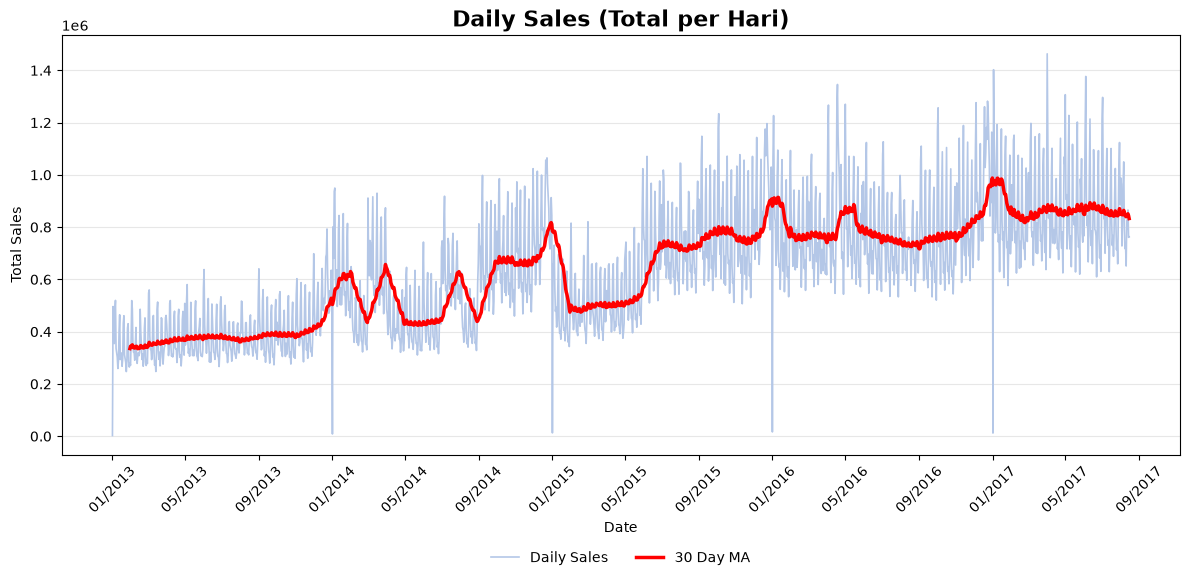

In [55]:
plt.figure(figsize=(12, 6))

plt.plot(daily["date"], daily["sales"], color="#B4C7E7", linewidth=1.2, label="Daily Sales")
plt.plot(daily["date"], daily["SMA_30"], color="red", linewidth=2.5, label="30 Day MA")

plt.title("Daily Sales (Total per Hari)", fontsize=16, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Memeriksa Stationer Dengan ADF

In [56]:
from statsmodels.tsa.stattools import adfuller

In [57]:
ts_sales = (
    df_copy.groupby("date")["sales"]
    .sum()
    .sort_index()
)

In [58]:
'''Untuk memastikan data lengkap dan tidak ada yang kosong'''
ts_sales = ts_sales.asfreq("D")                                  
ts_sales = ts_sales.interpolate() 

In [59]:
ts_sales

date
2013-01-01      2511.618999
2013-01-02    496092.417944
2013-01-03    361461.231124
2013-01-04    354459.677093
2013-01-05    477350.121229
                  ...      
2017-08-11    826373.722022
2017-08-12    792630.535079
2017-08-13    865639.677471
2017-08-14    760922.406081
2017-08-15    762661.935939
Freq: D, Name: sales, Length: 1688, dtype: float64

In [60]:
result = adfuller(ts_sales.dropna())
print("ADF Statistic:", result[0])
print("P-value:", result[1])

if result[1] < 0.05:
    print("Tolak H0: terdapat bukti bahwa series stasioner")
else:
    print("Gagal menolak H0: series belum terbukti stasioner")

ADF Statistic: -2.6210793419759604
P-value: 0.08871838554883776
Gagal menolak H0: series belum terbukti stasioner


## Memeriksa Stationer Dengan ACF

<Figure size 1500x500 with 0 Axes>

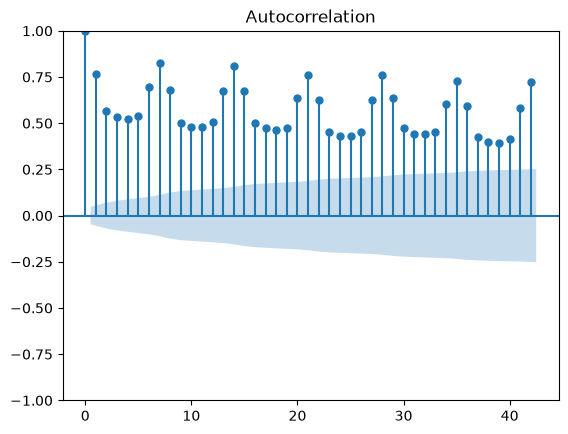

In [61]:
plt.figure(figsize=(15,5))

plot_acf(ts_sales, lags=42)

plt.show()

## Differencing Agar Data Stationer

In [62]:
ts_sales_diff = ts_sales.diff(7).dropna()

In [63]:
result = adfuller(ts_sales_diff.dropna())

print("ADF Statistic:", result[0])
print("P-value:", result[1])
print("Critical Values:", result[4])

if result[1] < 0.05:
    print("Tolak H0: terdapat bukti bahwa series stasioner")
else:
    print("Gagal menolak H0: series belum terbukti stasioner")

ADF Statistic: -11.135267900976347
P-value: 3.207045662674241e-20
Critical Values: {'1%': np.float64(-3.4343026006557427), '5%': np.float64(-2.863285847799246), '10%': np.float64(-2.5676994479374455)}
Tolak H0: terdapat bukti bahwa series stasioner


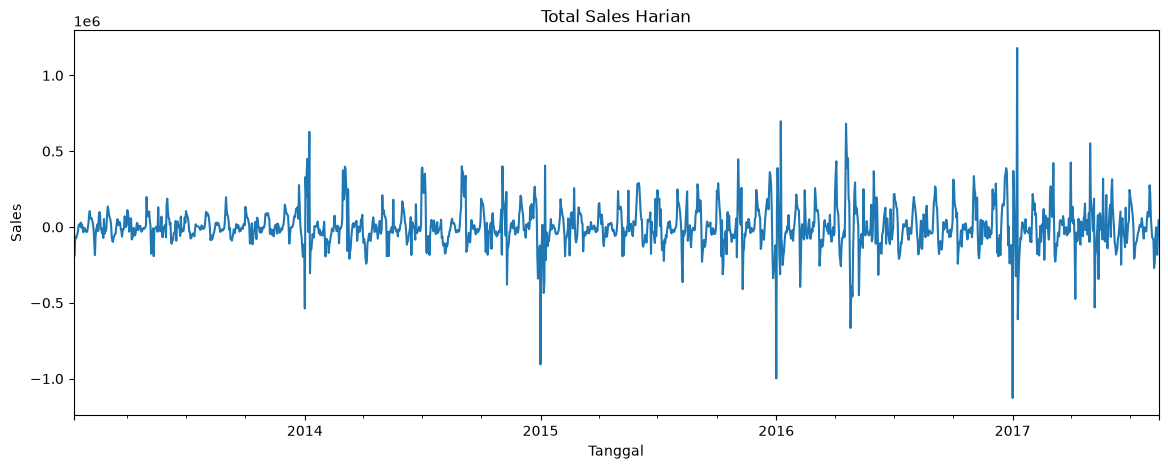

In [64]:
ts_sales_diff.plot(figsize=(14, 5))
plt.title("Total Sales Harian")
plt.xlabel("Tanggal")
plt.ylabel("Sales")
plt.show()

## ACF dan PACF

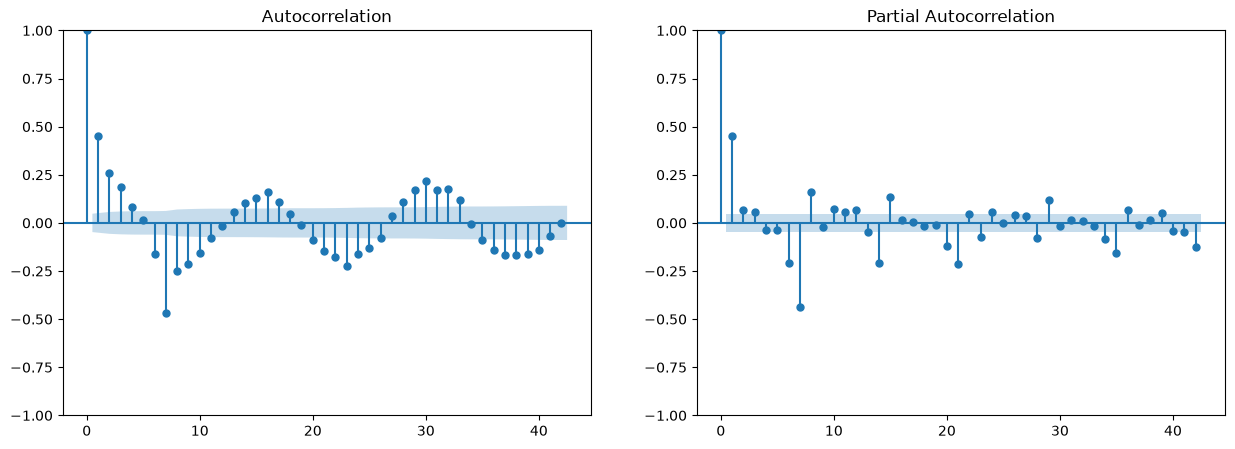

In [65]:
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
plot_acf(ts_sales_diff, lags=42, ax=plt.gca())

plt.subplot(1,2,2)
plot_pacf(ts_sales_diff, lags=42, ax=plt.gca())

plt.show()

## Menentukan Model Secara Manual Berdasarkan hasil ACF dan PACF

                          model  d       AIC       BIC  RMSE_test  MAPE_%  LjungBox_p  konvergen
0  SARIMA(1, 0, 1)x(1, 1, 1, 7)  0 -3064.061 -3037.135      0.081   6.687         0.0       True
1  SARIMA(1, 0, 1)x(0, 1, 1, 7)  0 -3068.100 -3046.560      0.081   6.701         0.0       True
2  SARIMA(0, 1, 1)x(0, 1, 1, 7)  1 -3009.701 -2993.547      0.082   7.000         0.0       True
3  SARIMA(3, 0, 0)x(0, 1, 1, 7)  0 -3068.262 -3041.332      0.082   6.834         0.0       True
4  SARIMA(2, 0, 0)x(0, 1, 1, 7)  0 -3020.457 -2998.913      0.083   7.060         0.0       True
5  SARIMA(1, 0, 0)x(1, 1, 1, 7)  0 -2978.368 -2956.825      0.084   7.132         0.0       True
6  SARIMA(1, 0, 0)x(0, 1, 1, 7)  0 -2970.436 -2954.279      0.085   7.285         0.0       True


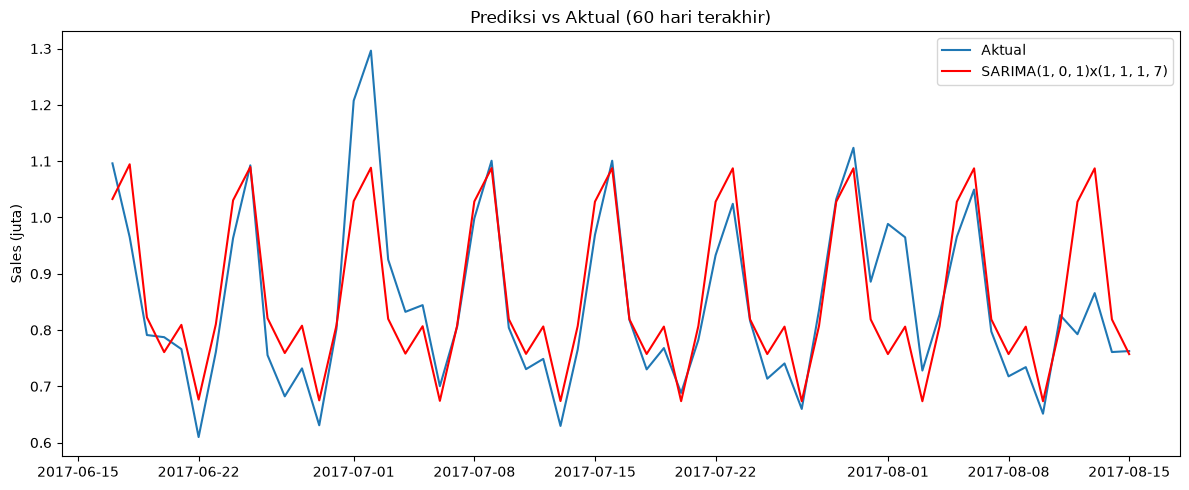

In [66]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")

ts = ts_sales / 1e6            # ts_sales = versi asfreq("D") + interpolate, ASLI (bukan hasil diff)
horizon = 60
train, test = ts.iloc[:-horizon], ts.iloc[-horizon:]

kandidat = [
    # jalur baru: d=0, D=1 (dari ACF/PACF diff(7))
    ((1,0,0), (0,1,1,7)),
    ((1,0,1), (0,1,1,7)),
    ((2,0,0), (0,1,1,7)),
    ((3,0,0), (0,1,1,7)),
    ((1,0,0), (1,1,1,7)),
    ((1,0,1), (1,1,1,7)),
    ((0,1,1), (0,1,1,7)),
]

rows, prediksi = [], {}
for order, seas in kandidat:
    try:
        m = SARIMAX(train, order=order, seasonal_order=seas,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        fc = m.get_forecast(horizon).predicted_mean
        rmse = np.sqrt(np.mean((test.values - fc.values) ** 2))
        mape = np.mean(np.abs((test.values - fc.values) / test.values)) * 100
        lb_p = acorr_ljungbox(m.resid.iloc[8:], lags=[14], return_df=True)["lb_pvalue"].iloc[0]
        nama = f"SARIMA{order}x{seas}"
        rows.append({"model": nama, "d": order[1], "AIC": m.aic, "BIC": m.bic,
                     "RMSE_test": rmse, "MAPE_%": mape, "LjungBox_p": lb_p,
                     "konvergen": m.mle_retvals.get("converged", None)})
        prediksi[nama] = fc
    except Exception as e:
        print("Gagal:", order, seas, "->", e)

tabel = pd.DataFrame(rows).sort_values("RMSE_test").reset_index(drop=True)
print(tabel.round(3).to_string())

terbaik = tabel.loc[0, "model"]
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Aktual", color="#1f77b4")
plt.plot(test.index, prediksi[terbaik], label=terbaik, color="red")
plt.title("Prediksi vs Aktual (60 hari terakhir)")
plt.ylabel("Sales (juta)"); plt.legend(); plt.tight_layout(); plt.show()

## Menetukan Model Dengan Auto ARIMA

In [67]:
from pmdarima import auto_arima

# auto_arima akan mencari model terbaik secara otomatis
stepwise_model = auto_arima(ts_sales, 
                            start_p=0, max_p=3,
                            start_q=0, max_q=3,
                            d=1,                # Differencing otomatis/manual
                            seasonal=True,      # Karena ada pola musiman per 7 lag
                            m=7,                # Periode musiman (mingguan = 7)
                            trace=True,
                            error_action='ignore',  
                            suppress_warnings=True, 
                            stepwise=True)

print(stepwise_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(1,0,1)[7] intercept   : AIC=44288.517, Time=1.64 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=45213.427, Time=0.10 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=44534.552, Time=0.66 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=44748.409, Time=1.57 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=45211.441, Time=0.07 sec
 ARIMA(0,1,0)(0,0,1)[7] intercept   : AIC=44849.500, Time=0.48 sec
 ARIMA(0,1,0)(1,0,0)[7] intercept   : AIC=44612.520, Time=0.38 sec
 ARIMA(0,1,0)(2,0,1)[7] intercept   : AIC=44290.289, Time=3.16 sec
 ARIMA(0,1,0)(1,0,2)[7] intercept   : AIC=44290.015, Time=3.04 sec
 ARIMA(0,1,0)(0,0,2)[7] intercept   : AIC=44695.992, Time=1.19 sec
 ARIMA(0,1,0)(2,0,0)[7] intercept   : AIC=44478.273, Time=0.93 sec
 ARIMA(0,1,0)(2,0,2)[7] intercept   : AIC=inf, Time=4.99 sec
 ARIMA(1,1,0)(1,0,1)[7] intercept   : AIC=inf, Time=2.42 sec
 ARIMA(0,1,1)(1,0,1)[7] intercept   : AIC=44138.441, Time=2.05 sec
 ARIMA(0,1,1)(1,0,0)[7] interce

## Membandingkan Hasil Manual dengan Auto Arima

In [68]:
import numpy as np, pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from pmdarima import auto_arima

ts = ts_sales / 1e6                     # ts_sales = versi asfreq("D") + interpolate
horizon = 60
train, test = ts.iloc[:-horizon], ts.iloc[-horizon:]

def evaluasi(nama, order, seas):
    m = SARIMAX(train, order=order, seasonal_order=seas,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
    fc = m.get_forecast(horizon).predicted_mean
    rmse = np.sqrt(np.mean((test.values - fc.values) ** 2))
    mape = np.mean(np.abs((test.values - fc.values) / test.values)) * 100
    lb_p = acorr_ljungbox(m.resid.iloc[8:], lags=[14], return_df=True)["lb_pvalue"].iloc[0]
    return {"model": nama, "AIC": m.aic, "RMSE_test": rmse, "MAPE_%": mape, "LjungBox_p": lb_p}

hasil = []

# 1. Model manual
hasil.append(evaluasi("Manual: (1,0,1)x(1,1,1,7)", (1,0,1), (1,1,1,7)))

# 2. Model hasil auto_arima (intercept diabaikan, nilainya sangat kecil)
hasil.append(evaluasi("Auto: (2,1,2)x(2,0,2,7)", (2,1,2), (2,0,2,7)))

# 3. auto_arima dengan pengaturan lebih tepat: data skala juta, hanya data latih, D=1 dipaksa
auto = auto_arima(train, seasonal=True, m=7, d=0, D=1,
                  start_p=0, max_p=3, start_q=0, max_q=3,
                  start_P=0, max_P=2, start_Q=0, max_Q=2,
                  stepwise=True, trace=True, error_action="ignore", suppress_warnings=True)
print("auto_arima baru:", auto.order, auto.seasonal_order)
hasil.append(evaluasi(f"auto_arima baru: {auto.order}x{auto.seasonal_order}", auto.order, auto.seasonal_order))

print(pd.DataFrame(hasil).sort_values("RMSE_test").round(3).to_string(index=False))

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,1,0)[7] intercept   : AIC=-1827.494, Time=0.69 sec
 ARIMA(1,0,0)(1,1,0)[7] intercept   : AIC=-2612.928, Time=3.57 sec
 ARIMA(0,0,1)(0,1,1)[7] intercept   : AIC=-2781.587, Time=4.36 sec
 ARIMA(0,0,0)(0,1,0)[7]             : AIC=-1829.109, Time=0.52 sec
 ARIMA(0,0,1)(0,1,0)[7] intercept   : AIC=-2117.479, Time=0.82 sec
 ARIMA(0,0,1)(1,1,1)[7] intercept   : AIC=inf, Time=8.60 sec
 ARIMA(0,0,1)(0,1,2)[7] intercept   : AIC=-2795.565, Time=16.91 sec
 ARIMA(0,0,1)(1,1,2)[7] intercept   : AIC=-2777.702, Time=16.96 sec
 ARIMA(0,0,0)(0,1,2)[7] intercept   : AIC=-2395.435, Time=8.46 sec
 ARIMA(1,0,1)(0,1,2)[7] intercept   : AIC=inf, Time=31.77 sec
 ARIMA(0,0,2)(0,1,2)[7] intercept   : AIC=-2888.024, Time=19.01 sec
 ARIMA(0,0,2)(0,1,1)[7] intercept   : AIC=-2871.483, Time=12.05 sec
 ARIMA(0,0,2)(1,1,2)[7] intercept   : AIC=-2868.118, Time=16.12 sec
 ARIMA(0,0,2)(1,1,1)[7] intercept   : AIC=inf, Time=18.06 sec
 ARIMA(1,0,2)(0,1,2)[7] interc

## Hasil Prediksi

1688 <Day>
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8901      0.013     68.312      0.000       0.865       0.916
ma.L1         -0.4713      0.012    -40.524      0.000      -0.494      -0.449
ar.S.L7        0.0184      0.019      0.954      0.340      -0.019       0.056
ma.S.L7       -0.9439      0.009   -105.654      0.000      -0.961      -0.926
sigma2         0.0085      0.000     81.944      0.000       0.008       0.009
            prediksi  batas_bawah  batas_atas       hari
2017-08-16     0.756        0.575       0.936  Wednesday
2017-08-17     0.632        0.436       0.827   Thursday
2017-08-18     0.772        0.565       0.979     Friday
2017-08-19     0.975        0.760       1.191   Saturday
2017-08-20     1.045        0.824       1.267     Sunday
2017-08-21     0.793        0.566       1.020     Monday
2017-08-22     0.742        0.511    

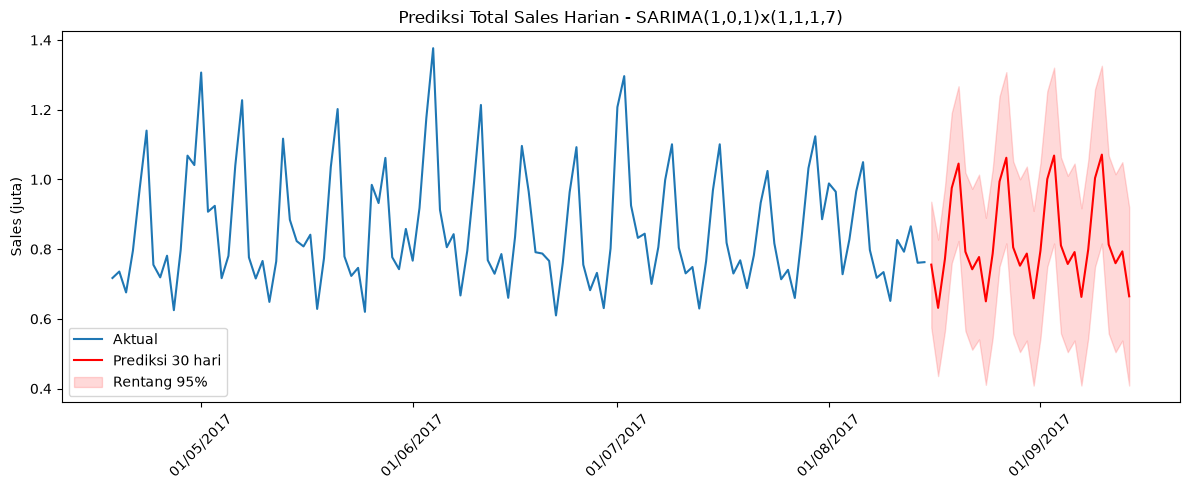


Total prediksi 30 hari  : 24.78 juta
Rata-rata hari kerja    : 0.753 juta
Rata-rata akhir pekan   : 1.028 juta
Hari tertinggi          : 2017-09-10 (1.071 juta)
Hari terendah           : 2017-08-17 (0.632 juta)


In [70]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.sarimax import SARIMAX

ts = ts_sales / 1e6                     # ts_sales = versi asfreq("D") + interpolate
print(len(ts), ts.index.freq)           # harus: 1688 <Day>

# 1. Fit ulang dengan SELURUH data
model_final = SARIMAX(ts, order=(1,0,1), seasonal_order=(1,1,1,7),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
print(model_final.summary().tables[1])  # koefisien model

# 2. Prediksi 30 hari
n_hari = 30
hasil = model_final.get_forecast(n_hari).summary_frame(alpha=0.05)[["mean", "mean_ci_lower", "mean_ci_upper"]]
hasil.columns = ["prediksi", "batas_bawah", "batas_atas"]
hasil.index = pd.date_range(start=ts.index[-1] + pd.Timedelta(days=1), periods=n_hari, freq="D")
hasil["hari"] = hasil.index.day_name()
print(hasil.round(3).to_string())

# 3. Grafik
plt.figure(figsize=(12, 5))
plt.plot(ts.index[-120:], ts.iloc[-120:], label="Aktual", color="#1f77b4")
plt.plot(hasil.index, hasil["prediksi"], label="Prediksi 30 hari", color="red")
plt.fill_between(hasil.index, hasil["batas_bawah"], hasil["batas_atas"], color="red", alpha=0.15, label="Rentang 95%")
plt.title("Prediksi Total Sales Harian - SARIMA(1,0,1)x(1,1,1,7)")
plt.ylabel("Sales (juta)")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

# 4. Angka ringkas
akhir_pekan = hasil["hari"].isin(["Saturday", "Sunday"])
print(f"\nTotal prediksi 30 hari  : {hasil['prediksi'].sum():.2f} juta")
print(f"Rata-rata hari kerja    : {hasil.loc[~akhir_pekan, 'prediksi'].mean():.3f} juta")
print(f"Rata-rata akhir pekan   : {hasil.loc[akhir_pekan, 'prediksi'].mean():.3f} juta")
print(f"Hari tertinggi          : {hasil['prediksi'].idxmax().date()} ({hasil['prediksi'].max():.3f} juta)")
print(f"Hari terendah           : {hasil['prediksi'].idxmin().date()} ({hasil['prediksi'].min():.3f} juta)")

# Ekstrak Data

## Data Untuk Dashboard

In [72]:
df_tableau = df_copy[["date", "store_nbr", "family", "sales", "onpromotion"]].copy()

In [73]:
df_tableau.to_csv("data_tableau.csv", index=False)